# Import Necessary Libraries


In [2]:
from sklearn.metrics import accuracy_score
import xgboost as xgb
from sklearn.model_selection import train_test_split

## Handling Accented and Special Characters in Player Stats

In [3]:
import pandas as pd
from unidecode import unidecode

# load the dataset containing PLAYER STATS2 times 

player_stats_df = pd.read_csv(
    "/home/csusers/jiayi.teh/CPSC502/nhl-prospects/player_stats.csv",
    encoding="latin1"
)
print(player_stats_df.shape)

# make a copy of the dataset
player_stats_cleaned = player_stats_df.copy()

# select all columns which are either string or object
string_cols = player_stats_cleaned.select_dtypes(include="object").columns
for col in string_cols:
    print(f"col : {col}")
    
    # Step 3: Create a new list to hold cleaned values
    cleaned_values = []

    # Step 4: Loop through each value in the column
    for val in player_stats_cleaned[col]:
        if pd.notna(val):  # if the value is not NaN
            # Convert the value to string and remove accents / special characters
            clean_val = unidecode(str(val))
            cleaned_values.append(clean_val)
        else:
            # Keep NaN values as isreate
            cleaned_values.append(val)

    # Step 5: Replace the original column with cleaned values
    player_stats_cleaned[col] = cleaned_values

# save the cleaned data to a new .csv
print(player_stats_cleaned.columns)
player_stats_cleaned.to_csv("/home/csusers/jiayi.teh/CPSC502/nhl-prospects/pre_draft.csv", index = False)
    

(402522, 17)
col : PLAYER_URL
col : PLAYER_NAME
col : FIRST_NAME
col : LAST_NAME
col : PRIMARY_POS
col : SECONDARY_POS
col : LEAGUE
col : LEAGUE_YEAR
Index(['ROW_ID', 'PLAYER_URL', 'PLAYER_ID', 'PLAYER_NAME', 'FIRST_NAME',
       'LAST_NAME', 'PRIMARY_POS', 'SECONDARY_POS', 'G', 'A', 'GP', 'PIM',
       '+/-', 'LEAGUE', 'LEAGUE_YEAR', 'P', 'PPG'],
      dtype='object')


## Handling Accented and Special Characters in Player Dim

In [4]:

# load the dataset containing PLAYER DIM

player_dim_df = pd.read_csv(
    "/home/csusers/jiayi.teh/CPSC502/nhl-prospects/player_dim.csv",
    encoding="latin1"
)

# make a copy of the dataset
player_dim_cleaned_df = player_dim_df.copy()

# select all columns which are either string or object
string_cols = player_dim_cleaned_df.select_dtypes(include="object").columns
for col in string_cols:
    print(f"col : {col}")
    
    # Step 3: Create a new list to hold cleaned values
    cleaned_values = []

    # Step 4: Loop through each value in the column
    for val in player_dim_cleaned_df[col]:
        if pd.notna(val):  # if the value is not NaN
            # Convert the value to string and remove accents / special characters
            clean_val = unidecode(str(val))
            cleaned_values.append(clean_val)
        else:
            # Keep NaN values as-is
            cleaned_values.append(val)

    # Step 5: Replace the original column with cleaned values
    player_dim_cleaned_df[col] = cleaned_values

# save the cleaned data to a new .csv
player_dim_cleaned_df.to_csv("/home/csusers/jiayi.teh/CPSC502/nhl-prospects/player_dim_cleaned.csv", index = False)
    


col : FIRST_NAME
col : LAST_NAME
col : DATE_OF_BIRTH
col : PLACE_OF_BIRTH
col : NATIONALITY
col : SHOOTS
col : CONTRACT_THRU


# Merge Player Stats and Player Dim together

In [5]:
# create new df called pre draft data so we can store just draft data in there 
# merge cleaned player stats with cleaned player dim on player id
pre_draft_df = player_stats_cleaned.merge(
    player_dim_cleaned_df[["PLAYER_ID","DATE_OF_BIRTH","PLACE_OF_BIRTH",
                          "NATIONALITY","HEIGHT_CM","WEIGHT_KG","SHOOTS",
                          "CONTRACT_THRU","DRAFT_YEAR","DRAFT_ROUND","DRAFT_OVERALL"
                          ]
],
    on="PLAYER_ID",
    how="left"
)

# get shape before dropping duplicates
print(pre_draft_df.columns)
print(pre_draft_df.shape)

# get shape after 
# ping duplicates
pre_draft_df = pre_draft_df.drop_duplicates()
print(pre_draft_df.shape)


Index(['ROW_ID', 'PLAYER_URL', 'PLAYER_ID', 'PLAYER_NAME', 'FIRST_NAME',
       'LAST_NAME', 'PRIMARY_POS', 'SECONDARY_POS', 'G', 'A', 'GP', 'PIM',
       '+/-', 'LEAGUE', 'LEAGUE_YEAR', 'P', 'PPG', 'DATE_OF_BIRTH',
       'PLACE_OF_BIRTH', 'NATIONALITY', 'HEIGHT_CM', 'WEIGHT_KG', 'SHOOTS',
       'CONTRACT_THRU', 'DRAFT_YEAR', 'DRAFT_ROUND', 'DRAFT_OVERALL'],
      dtype='object')
(402522, 27)
(402522, 27)


# Dropping Unneccesary Columns


In [6]:
pre_draft_df = pre_draft_df.drop("CONTRACT_THRU", axis=1)
pre_draft_df = pre_draft_df.drop("PLACE_OF_BIRTH", axis=1)

## Standardize all nhl to NHL to make sure we extract all before checking leagues which are not equal to NHL

In [7]:
# replace and make sure that all league names are capitalized
pre_draft_df["LEAGUE"] = pre_draft_df["LEAGUE"].str.upper()

# save the post draft/ ubsequent nhl performance stats for later
nhl_stats_df = pre_draft_df[pre_draft_df["LEAGUE"] == "NHL"]
print(nhl_stats_df.shape)

# extract row where it does not meet column = NHL
pre_draft_df = pre_draft_df[pre_draft_df["LEAGUE"] != "NHL"]

# Total Rows for Players with Pre Draft Stats
print(pre_draft_df.shape)


(29339, 25)
(373183, 25)


## Case 1 : If player has pre-draft stats but no Draft Year 
How do we clean them 
What does this mean? -> the player was probably Free Agent, and that their pre-draft stats are AHL- related, explain AHL. 
How many fall under case where they have pre-draft stats but no draft year
if they were not involved in draft 
in this case if no draft year we should have already established that we will drop those without draft year, because draft year is one of the main features we're interested in. cause if we know what draft year, then we know which other players to compare them to 
(since we're training our ml model based on models and stuff), and merely interested in the pick of that player (what pick are they), then if a player does not have the draft year, they may not have joined the NHL the traditional way, so there is no point of including them in the data bc we are interested in those included in the DRAFT and we want information on those who were involved in draft so we can train the ML with the data of those involved
## Case 2 : if they were involved in draft but no draft year - some because the draft information too old so no draft year in the original dataset obtained from kaggle
we drop them. why -> standardize them
You cannot use a row without a draft year if you’re predicting draft pick, round, or anything draft-related.
check code below, very important
#keep the ones with KNOWN draft years for ML training <- make sure to include this in report
## Case 3 : We added last 2-3 years of stats prior to draft, but some have multiple stats because they were in more than one league a year. 
Example : Alex Goligoski. we include these stats anyway because we care about the total stats they make per entire season (include this sentence in report)

In [8]:
print(pre_draft_df.loc[
    pre_draft_df["DRAFT_YEAR"].isna(),
    ["PLAYER_ID", "FIRST_NAME", "LAST_NAME", "LEAGUE", "LEAGUE_YEAR", "G", "A", "GP", "DRAFT_YEAR"]
])
print("Test")

# DEAL WITH TWO SEPARATE CASES 
# CASE 1 : WE WILL SAVE THE STATS OF THOSE WHO DO NOT HAVE DRAFT YEAR (COULD EITHER BE FREE AGENT OR JUST MISSING DRAFT YEAR)
# Stats for players without draft year
no_draft_year_df = pre_draft_df[pre_draft_df["DRAFT_YEAR"].isna()]

# Stats for players without draft year
undrafted_stats = pre_draft_df[pre_draft_df["DRAFT_YEAR"].isna()]
print(f"LIST OF ROWS FOR THOSE THAT DO NOT HAVE DRAFT YEAR IN DATA: {undrafted_stats.shape}")

# then we keep here and change pre_draft_df to include the ones where draft year is NOT NA so we can use them for model training
pre_draft_df = pre_draft_df[pre_draft_df["DRAFT_YEAR"].notna()]
print(f"LIST OF ROWS FOR THOSE THAT HAVE DRAFT YEAR IN DATA: {pre_draft_df.shape}")

        PLAYER_ID FIRST_NAME   LAST_NAME   LEAGUE LEAGUE_YEAR     G     A  \
29339     28536.0       Mike    Kaszycki      AHL   1981-1982  36.0  82.0   
29340     47412.0     Gordie       Clark      AHL   1981-1982  50.0  51.0   
29341    100282.0      Wayne      Schaab      AHL   1981-1982  27.0  69.0   
29342     24027.0        Guy  Carbonneau      AHL   1981-1982  27.0  67.0   
29343     71450.0        Wes      Jarvis      AHL   1981-1982  31.0  61.0   
...           ...        ...         ...      ...         ...   ...   ...   
402517   659923.0      Kevin      Gannon  USHS-MA   2018-2019   NaN   NaN   
402518   665719.0      Kevin     Canaday  USHS-MA   2018-2019   NaN   NaN   
402519   552740.0     Cooper     Griffin  USHS-MA   2018-2019   NaN   NaN   
402520   446192.0      Teddy        Goss  USHS-MA   2018-2019   NaN   NaN   
402521   665720.0      Hagan        Ward  USHS-MA   2018-2019   NaN   NaN   

          GP  DRAFT_YEAR  
29339   80.0         NaN  
29340   80.0         

In [9]:


# Clean out LEAGUE_YEAR row:
pre_draft_df["LEAGUE_YEAR"] = (
    pre_draft_df["LEAGUE_YEAR"]
    .astype(str)
    .str.strip()
    .replace(["NA", "N/A", "--", "-", ""], pd.NA)
)

# 1. Parse league start year from "2003-2004"
pre_draft_df["LEAGUE_START"] = (
    # get the column league year and convert it to type string
    pre_draft_df["LEAGUE_YEAR"]
    .astype(str)
    # split it by the delimiter "-"
    .str.split("-")
    # get the first one cause thats the start year
    .str[0]
    # cast it back to type int
    .astype(int)
)

print(pre_draft_df["LEAGUE_START"])
# ensure DRAFT_YEAR is integer
pre_draft_df["DRAFT_YEAR"] = pre_draft_df["DRAFT_YEAR"].astype(int)

# compute years before draft
pre_draft_df["YEARS_BEFORE_DRAFT"] = pre_draft_df["DRAFT_YEAR"] - pre_draft_df["LEAGUE_START"]

# keep only last 3 years before draft for each player
pre_draft_df = pre_draft_df[pre_draft_df["YEARS_BEFORE_DRAFT"].isin([1, 2, 3])]

# sort the values
pre_draft_df = pre_draft_df.sort_values(
    ["PLAYER_ID", "YEARS_BEFORE_DRAFT"]
)

print(f"list of rows in dataset after getting past 2-3 year stats: {pre_draft_df.shape}")

pre_draft_df.head()
pre_draft_df.to_csv("/home/csusers/jiayi.teh/CPSC502/nhl-prospects/pre_draft_stats.csv", index = False)
pre_draft_df.isna().sum()



37154     1997
37908     1998
39341     2000
39690     2001
40257     2001
          ... 
386164    2011
386511    2012
386593    2012
395805    2011
396149    2012
Name: LEAGUE_START, Length: 6551, dtype: int64
list of rows in dataset after getting past 2-3 year stats: (2060, 27)


ROW_ID                   0
PLAYER_URL               0
PLAYER_ID                0
PLAYER_NAME              0
FIRST_NAME               0
LAST_NAME                0
PRIMARY_POS              0
SECONDARY_POS         1480
G                        8
A                        8
GP                      13
PIM                     69
+/-                    387
LEAGUE                   0
LEAGUE_YEAR              0
P                        8
PPG                     23
DATE_OF_BIRTH            0
NATIONALITY              0
HEIGHT_CM                0
WEIGHT_KG                0
SHOOTS                   0
DRAFT_YEAR               0
DRAFT_ROUND              0
DRAFT_OVERALL            0
LEAGUE_START             0
YEARS_BEFORE_DRAFT       0
dtype: int64

# Converting Age into Age at the Year of Draft

In [10]:
pre_draft_df["BIRTH_YEAR"] = pre_draft_df["DATE_OF_BIRTH"].str[:4].astype(int)
pre_draft_df["DRAFT_YEAR"] = pre_draft_df["DRAFT_YEAR"].astype(int)

# Compute age
pre_draft_df["AGE"] = pre_draft_df["DRAFT_YEAR"] - pre_draft_df["BIRTH_YEAR"]

# drop those columns after
pre_draft_df.drop(columns=["DATE_OF_BIRTH", "BIRTH_YEAR"], inplace=True)



# DELETE THIS ONE HERE


In [11]:
# Get Sidney Crosby's AGE
age = pre_draft_df.loc[
    pre_draft_df["PLAYER_NAME"].str.contains("Sidney Crosby", case=False, regex=False),
    "AGE"
].values

# Print safely
if len(age) > 0:
    print("Sidney Crosby's age at draft:", age[0])
else:
    print("Player not found")

Sidney Crosby's age at draft: 18


# Handling Missing Data

## 1. Imputation of G, A, GP, PIM, +/-, P

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

stats_cols = ["G", "A", "P", "GP", "PIM", "+/-"]


# Fill missing stats using **median of the same player**
pre_draft_df[stats_cols] = pre_draft_df.groupby("PLAYER_ID")[stats_cols]\
                                      .transform(lambda x: x.fillna(x.median()))
                        


pre_draft_df.isna().sum()
    

ROW_ID                   0
PLAYER_URL               0
PLAYER_ID                0
PLAYER_NAME              0
FIRST_NAME               0
LAST_NAME                0
PRIMARY_POS              0
SECONDARY_POS         1480
G                        0
A                        0
GP                       0
PIM                     17
+/-                    158
LEAGUE                   0
LEAGUE_YEAR              0
P                        0
PPG                     23
NATIONALITY              0
HEIGHT_CM                0
WEIGHT_KG                0
SHOOTS                   0
DRAFT_YEAR               0
DRAFT_ROUND              0
DRAFT_OVERALL            0
LEAGUE_START             0
YEARS_BEFORE_DRAFT       0
AGE                      0
dtype: int64

## 2. Missing PPG 


In [13]:
pre_draft_df["PPG"] = pre_draft_df["P"] / pre_draft_df["GP"]
num_missing = pre_draft_df["PPG"].isna().sum()

print(num_missing)

10


# 3. Missing Secondary Position

In [14]:
pre_draft_df["SECONDARY_POS"] = pre_draft_df["SECONDARY_POS"].fillna("None")

num_missing = pre_draft_df["SECONDARY_POS"].isna().sum()

print(num_missing)

0


In [15]:
print(
    pre_draft_df[
        (pre_draft_df["DRAFT_YEAR"] == 2018) &
        (pre_draft_df["DRAFT_ROUND"] == 1)
    ]
    .sort_values(by="DRAFT_OVERALL")
    [["PLAYER_NAME", "DRAFT_OVERALL", "DRAFT_YEAR", "DRAFT_ROUND"]]
    .to_string(index=False)
)


              PLAYER_NAME  DRAFT_OVERALL  DRAFT_YEAR  DRAFT_ROUND
        Rasmus Dahlin (D)            1.0        2018          1.0
        Rasmus Dahlin (D)            1.0        2018          1.0
Andrei Svechnikov (RW/LW)            2.0        2018          1.0
Andrei Svechnikov (RW/LW)            2.0        2018          1.0
   Jesperi Kotkaniemi (C)            3.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Barrett Hayton (C)            5.0        2018          1.0
       Barrett Hayton (C)            5.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
         Quinn Hughes (D)            7.0        2018          1.0
         Q

# 4. Calculate Remaining Missing Data for Players that have missing data for other seasons
Earlier we grouped by Player and get the median since they might have stats from other seasons, so we used the median. However in the case where the player does not have any data from other seasons, we use MICE to compute the missing data


In [16]:

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

stats_cols = ["PIM", "+/-", "PPG"]

before = pre_draft_df[stats_cols].copy()

# Initialize MICE (Iterative Imputer)
mice_imputer = IterativeImputer(max_iter=10, random_state=0)

# Only select numeric columns for MICE
pre_draft_df[stats_cols] = mice_imputer.fit_transform(pre_draft_df[stats_cols])

# Check that all missing values are gone
print(pre_draft_df[stats_cols].isna().sum())



PIM    0
+/-    0
PPG    0
dtype: int64


In [17]:
print(
    pre_draft_df[
        (pre_draft_df["DRAFT_YEAR"] == 2018) &
        (pre_draft_df["DRAFT_ROUND"] == 1)
    ]
    .sort_values(by="DRAFT_OVERALL")
    [["PLAYER_NAME", "DRAFT_OVERALL", "DRAFT_YEAR", "DRAFT_ROUND"]]
    .to_string(index=False)
)

              PLAYER_NAME  DRAFT_OVERALL  DRAFT_YEAR  DRAFT_ROUND
        Rasmus Dahlin (D)            1.0        2018          1.0
        Rasmus Dahlin (D)            1.0        2018          1.0
Andrei Svechnikov (RW/LW)            2.0        2018          1.0
Andrei Svechnikov (RW/LW)            2.0        2018          1.0
   Jesperi Kotkaniemi (C)            3.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Brady Tkachuk (LW)            4.0        2018          1.0
       Barrett Hayton (C)            5.0        2018          1.0
       Barrett Hayton (C)            5.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
     Filip Zadina (LW/RW)            6.0        2018          1.0
         Quinn Hughes (D)            7.0        2018          1.0
         Q

In [18]:
pre_draft_df["DRAFT_YEAR"].max() # 2019
pre_draft_df["DRAFT_YEAR"].min() #1996



np.int64(1996)

# Sort by Draft Year

In [19]:
pre_draft_df = pre_draft_df.sort_values("DRAFT_YEAR")
pre_draft_df.head

pre_draft_df = pre_draft_df.sort_values("DRAFT_YEAR")



# Flattening out Draft Statistics 
- before : model assumes multiple stats per player correspond to different players 
- after : model knows that it corresponds to one player

- Case 1 : Error 1
The error means your data has at least one player who has two different rows for the same YEARS_BEFORE_DRAFT. In the NHL, this usually happens for two reasons:

Mid-Season Trades: A player played for two different teams in the same league in one year.

League Hopping: A player played in two different leagues in the same season (e.g., 20 games in the OHL and 5 games in the AHL).

- we use pivot_table. This allows us to tell the computer: "If you find two rows for one year, add them together.
- If a player got traded mid-season, you don't want the model to only see half of their goals. By using aggfunc='sum', you ensure that G_Y1 represents their total goals for that entire year, regardless of how many teams they played for.

In [20]:
# # See exactly what league strings exist in your data
# print("Y1 leagues:", sorted(final_df['LEAGUE_Y1'].dropna().unique()))
# print("Y2 leagues:", sorted(final_df['LEAGUE_Y2'].dropna().unique()))
# print("Y2 leagues:", sorted(final_df['LEAGUE_Y3'].dropna().unique()))


In [21]:
# 1. Static info
static_info = [
    'PLAYER_ID', 'PLAYER_NAME', 'DRAFT_YEAR', 'DRAFT_ROUND', 'DRAFT_OVERALL',
    'PRIMARY_POS', 'SECONDARY_POS', 'NATIONALITY', 'SHOOTS', 'HEIGHT_CM', 'WEIGHT_KG'
]

# 2. Pivot stats
final_df = pre_draft_df.pivot_table(
    index=static_info,
    columns='YEARS_BEFORE_DRAFT',
    values=['G', 'A', 'GP', 'P', 'PIM', '+/-'],
    aggfunc='sum'
)
final_df.columns = [f"{col[0]}_Y{col[1]}" for col in final_df.columns]

# 3. Pivot league
league_pivot = pre_draft_df.pivot_table(
    index=static_info,
    columns='YEARS_BEFORE_DRAFT',
    values='LEAGUE',
    aggfunc='first'
)
league_pivot.columns = [f"LEAGUE_Y{col}" for col in league_pivot.columns]

# 4. Join
final_df = final_df.join(league_pivot).reset_index()

# 5. Fill categorical NaNs FIRST
final_df['LEAGUE_Y1'] = final_df['LEAGUE_Y1'].fillna('UNKNOWN')
final_df['LEAGUE_Y2'] = final_df['LEAGUE_Y2'].fillna('NONE')
final_df['LEAGUE_Y3'] = final_df['LEAGUE_Y3'].fillna('NONE')
final_df['SECONDARY_POS'] = final_df['SECONDARY_POS'].fillna('NONE')

# 6. League strength mapping
league_strength = {
    'KHL': 5, 'SHL': 5, 'LIIGA': 5,
    'NLA': 4, 'DEL': 4, 'AHL': 4, 'CZECH': 4, 'NCAA': 4,
    'OHL': 4, 'WHL': 4, 'QMJHL': 4,
    'USHL': 3, 'BCHL': 3, 'AJHL': 3, 'OJHL': 3, 'CCHL': 3, 'SJHL': 3,
    'MJHL': 2, 'QJAAAHL': 2,
    'USHS-PREP': 2, 'USHS-MN': 2, 'USHS-MI': 2, 'USHS-MA': 2, 'USHS-NY': 2,
    'NONE': 0, 'UNKNOWN': 0,
}
final_df["LEAGUE_STR_Y1"] = final_df["LEAGUE_Y1"].map(league_strength).fillna(2)
final_df["LEAGUE_STR_Y2"] = final_df["LEAGUE_Y2"].map(league_strength).fillna(2)
final_df["LEAGUE_STR_Y3"] = final_df["LEAGUE_Y3"].map(league_strength).fillna(2)

# 7. Per-game stats — safe division BEFORE fillna(0)
for year in ['1', '2', '3']:
    gp = final_df[f'GP_Y{year}'].replace(0, np.nan)
    final_df[f'PPG_Y{year}']      = (final_df[f'P_Y{year}'] / gp).round(3)
    final_df[f'GPG_Y{year}']      = (final_df[f'G_Y{year}'] / gp).round(3)
    final_df[f'APG_Y{year}']      = (final_df[f'A_Y{year}'] / gp).round(3)
    final_df[f'PTS_PER_82_Y{year}'] = final_df[f'PPG_Y{year}'] * 82

# 7b. Position-adjusted PPG — added RIGHT HERE
pos_ppg_expectation = {'C': 0.9, 'LW': 0.8, 'RW': 0.8, 'W': 0.8, 'D': 0.5}
for year in ['1', '2', '3']:
    expectation = final_df['PRIMARY_POS'].map(pos_ppg_expectation).fillna(0.8)
    final_df[f'PPG_Y{year}_POSADJ'] = (
        final_df[f'PPG_Y{year}'] / expectation.replace(0, np.nan)
    ).fillna(0)
    
# 8. Z-score normalize within each league — must happen BEFORE fillna(0)
for stat in ['PPG_Y1', 'GPG_Y1', 'APG_Y1',
             'PPG_Y2', 'GPG_Y2', 'APG_Y2',
             'PPG_Y3', 'GPG_Y3', 'APG_Y3']:
    if 'Y1' in stat:
        group_col = 'LEAGUE_Y1'
    elif 'Y2' in stat:
        group_col = 'LEAGUE_Y2'
    else:
        group_col = 'LEAGUE_Y3'
    group_mean = final_df.groupby(group_col)[stat].transform('mean')
    group_std  = final_df.groupby(group_col)[stat].transform('std').replace(0, 1)
    final_df[f'{stat}_ZNORM'] = ((final_df[stat] - group_mean) / group_std).fillna(0)

# 9. GP confidence weighting — shrinks stats from small sample sizes
# Y1 = most recent (1 year before draft) → highest weight
# Y2 = 2 years before draft             → medium weight
# Y3 = 3 years before draft             → lowest weight
FULL_SEASON = 68
for year in ['1', '2', '3']:
    gp = final_df[f'GP_Y{year}']
    confidence = (gp / FULL_SEASON).clip(0, 1)
    for stat in ['PPG', 'GPG', 'APG']:
        final_df[f'{stat}_Y{year}_WEIGHTED'] = (
            final_df[f'{stat}_Y{year}_ZNORM'] * confidence
        )

# 10. Recency combined score — Y1 counts most, Y3 counts least
for stat in ['PPG', 'GPG', 'APG']:
    final_df[f'{stat}_RECENCY_SCORE'] = (
        final_df[f'{stat}_Y1_WEIGHTED'] * 1.5 +
        final_df[f'{stat}_Y2_WEIGHTED'] * 1.0 +
        final_df[f'{stat}_Y3_WEIGHTED'] * 0.5
    )

# 11. Fill ALL remaining numeric NaNs with 0 — must be LAST
numeric_cols = final_df.select_dtypes(include=['number']).columns
final_df[numeric_cols] = final_df[numeric_cols].fillna(0)

# 12. Verify
print("Shape:", final_df.shape)
print("NaNs remaining:", final_df.isnull().sum().sum())

check = ['Brett Leason (RW)', 'Jack Hughes (C)', 'Kaapo Kakko (RW)']
cols  = ['PLAYER_NAME',
         'GP_Y1', 'PPG_Y1_ZNORM', 'PPG_Y1_WEIGHTED',
         'GP_Y2', 'PPG_Y2_ZNORM', 'PPG_Y2_WEIGHTED',
         'GP_Y3', 'PPG_Y3_ZNORM', 'PPG_Y3_WEIGHTED',
         'PPG_RECENCY_SCORE']
print(final_df[final_df['PLAYER_NAME'].isin(check)][cols].to_string())

Shape: (927, 71)
NaNs remaining: 0
           PLAYER_NAME  GP_Y1  PPG_Y1_ZNORM  PPG_Y1_WEIGHTED  GP_Y2  PPG_Y2_ZNORM  PPG_Y2_WEIGHTED  GP_Y3  PPG_Y3_ZNORM  PPG_Y3_WEIGHTED  PPG_RECENCY_SCORE
803  Brett Leason (RW)   55.0      2.299135         1.859594   66.0      0.058148         0.056438   69.0      0.056632         0.056632           2.874146
890    Jack Hughes (C)   24.0      2.515172         0.887708   27.0      3.013826         1.196666    0.0      0.000000         0.000000           2.528228
919   Kaapo Kakko (RW)   45.0      1.117720         0.739668    6.0     -0.541863        -0.047811    0.0      0.000000         0.000000           0.000000


In [22]:
# Fill categorical NaNs
final_df['LEAGUE_Y2']     = final_df['LEAGUE_Y2'].fillna('NONE')
final_df['LEAGUE_Y1']     = final_df['LEAGUE_Y1'].fillna('UNKNOWN')
final_df['SECONDARY_POS'] = final_df['SECONDARY_POS'].fillna('NONE')

# Fill any other object columns
for col in final_df.select_dtypes(include='object').columns:
    final_df[col] = final_df[col].fillna('UNKNOWN')

print("NaNs remaining:", final_df.isnull().sum().sum())  # must be 0

NaNs remaining: 0


# Splitting Dataset into Testing and Training
- hold out method 

- we skip feature scaling cause we are exploring decisio ntree and learning to rank
- look into : dimension reduction

Next Steps: 
SCATTERPLOT OR HISTOGRAM!!
Helps to understand the dataset by showing how many features it has, what type of data each feature contains and how the data is distributed.


In [23]:
print(*final_df.columns, sep='\n')

PLAYER_ID
PLAYER_NAME
DRAFT_YEAR
DRAFT_ROUND
DRAFT_OVERALL
PRIMARY_POS
SECONDARY_POS
NATIONALITY
SHOOTS
HEIGHT_CM
WEIGHT_KG
+/-_Y1
+/-_Y2
+/-_Y3
A_Y1
A_Y2
A_Y3
G_Y1
G_Y2
G_Y3
GP_Y1
GP_Y2
GP_Y3
P_Y1
P_Y2
P_Y3
PIM_Y1
PIM_Y2
PIM_Y3
LEAGUE_Y1
LEAGUE_Y2
LEAGUE_Y3
LEAGUE_STR_Y1
LEAGUE_STR_Y2
LEAGUE_STR_Y3
PPG_Y1
GPG_Y1
APG_Y1
PTS_PER_82_Y1
PPG_Y2
GPG_Y2
APG_Y2
PTS_PER_82_Y2
PPG_Y3
GPG_Y3
APG_Y3
PTS_PER_82_Y3
PPG_Y1_POSADJ
PPG_Y2_POSADJ
PPG_Y3_POSADJ
PPG_Y1_ZNORM
GPG_Y1_ZNORM
APG_Y1_ZNORM
PPG_Y2_ZNORM
GPG_Y2_ZNORM
APG_Y2_ZNORM
PPG_Y3_ZNORM
GPG_Y3_ZNORM
APG_Y3_ZNORM
PPG_Y1_WEIGHTED
GPG_Y1_WEIGHTED
APG_Y1_WEIGHTED
PPG_Y2_WEIGHTED
GPG_Y2_WEIGHTED
APG_Y2_WEIGHTED
PPG_Y3_WEIGHTED
GPG_Y3_WEIGHTED
APG_Y3_WEIGHTED
PPG_RECENCY_SCORE
GPG_RECENCY_SCORE
APG_RECENCY_SCORE


In [24]:
# training = pre_draft_df
# N = len(training)
# np.random.seed(42)

# # 90% training for years < 2015
# train_mask = (np.random.binomial(1, 0.9, size=N) == 1) & (training["DRAFT_YEAR"] < 2015)

# # Remaining players before 2015 → test set
# test_mask = (~train_mask) & (training["DRAFT_YEAR"] < 2015)

# # All players 2015 + → final holdout set
# holdout_mask = ~(train_mask | test_mask)

# # -------------------------------------------------------------
# # Outcome variables for ML prediction
# # -------------------------------------------------------------
# pick = training["DRAFT_OVERALL"]                      # Continuous target
# first_round = (training["DRAFT_OVERALL"] <= 32).astype(int)  # Binary target

# Split dataset into training and testing

In [25]:
# # Number of rows
# N = len(pre_draft_df)

# # Train set: 90% random selection + year < 2016
# train_set = (np.random.binomial(1, 0.9, N) == 1) & (pre_draft_df["DRAFT_YEAR"] < 2016)

# # Test set: remaining 10% of year < 2016
# test_set = (~train_set) & (pre_draft_df["DRAFT_YEAR"] < 2016)

# # Holdout: all rows from 2016 and later
# holdout_set = ~(train_set | test_set)

# # Outcome variables
# pick = pre_draft_df["DRAFT_OVERALL"]
# first_round = (pre_draft_df["DRAFT_OVERALL"] <= 32).astype(int)

In [26]:

final_df.columns.get_loc("DRAFT_OVERALL")
X = final_df.loc[:, final_df.columns != "DRAFT_OVERALL"]
print(X.head)
# select column at index 26 
# ("Draft Overall")
# .values converts to numpy array and y is the target variable

y = final_df["DRAFT_OVERALL"].values



<bound method NDFrame.head of      PLAYER_ID              PLAYER_NAME  DRAFT_YEAR  DRAFT_ROUND PRIMARY_POS  \
0        158.0       Johan Franzen (LW)        2004          3.0          LW   
1        210.0        Frans Nielsen (C)        2002          3.0           C   
2        460.0  Alexander Steen (LW/RW)        2002          1.0          LW   
3        665.0       Carl Soderberg (C)        2004          2.0           C   
4       2621.0      Carl Gunnarsson (D)        2007          7.0           D   
..         ...                      ...         ...          ...         ...   
922   398450.0       Artemi Knyazev (D)        2019          2.0           D   
923   399353.0        Ty Dellandrea (C)        2018          1.0           C   
924   424496.0     Connor McMichael (C)        2019          1.0           C   
925   428795.0        Ville Heinola (D)        2019          1.0           D   
926   517438.0        Alexei Protas (C)        2019          3.0           C   

    SECON

# Convert our data into categorical data

In [27]:
final_df.dtypes

PLAYER_ID            float64
PLAYER_NAME           object
DRAFT_YEAR             int64
DRAFT_ROUND          float64
DRAFT_OVERALL        float64
                      ...   
GPG_Y3_WEIGHTED      float64
APG_Y3_WEIGHTED      float64
PPG_RECENCY_SCORE    float64
GPG_RECENCY_SCORE    float64
APG_RECENCY_SCORE    float64
Length: 71, dtype: object

# Trying with XGBoost Ranker

In [28]:
import xgboost as xgb
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ── 1. Define columns ─────────────────────────────────────────────────────────
junk_cols = ['PLAYER_ID', 'PLAYER_NAME', 'DRAFT_YEAR', 'DRAFT_ROUND', 'DRAFT_OVERALL']

keep_cols = [
    # Physical / identity
    'PRIMARY_POS', 'SECONDARY_POS', 'NATIONALITY', 'SHOOTS',
    'HEIGHT_CM', 'WEIGHT_KG',
    # Games played
    'GP_Y1', 'GP_Y2', 'GP_Y3',
    # League context
    'LEAGUE_Y1', 'LEAGUE_Y2', 'LEAGUE_Y3',
    'LEAGUE_STR_Y1', 'LEAGUE_STR_Y2', 'LEAGUE_STR_Y3',
    # Raw totals
    'G_Y1', 'A_Y1', 'P_Y1', 'PIM_Y1', '+/-_Y1',
    'G_Y2', 'A_Y2', 'P_Y2', 'PIM_Y2', '+/-_Y2',
    'G_Y3', 'A_Y3', 'P_Y3', 'PIM_Y3', '+/-_Y3',
    # Per game
    'PPG_Y1', 'GPG_Y1', 'APG_Y1',
    'PPG_Y2', 'GPG_Y2', 'APG_Y2',
    'PPG_Y3', 'GPG_Y3', 'APG_Y3',
    # League-normalized
    'PPG_Y1_ZNORM', 'GPG_Y1_ZNORM', 'APG_Y1_ZNORM',
    'PPG_Y2_ZNORM', 'GPG_Y2_ZNORM', 'APG_Y2_ZNORM',
    'PPG_Y3_ZNORM', 'GPG_Y3_ZNORM', 'APG_Y3_ZNORM',
    # GP-weighted
    'PPG_Y1_WEIGHTED', 'GPG_Y1_WEIGHTED', 'APG_Y1_WEIGHTED',
    'PPG_Y2_WEIGHTED', 'GPG_Y2_WEIGHTED', 'APG_Y2_WEIGHTED',
    'PPG_Y3_WEIGHTED', 'GPG_Y3_WEIGHTED', 'APG_Y3_WEIGHTED',
    # Recency combined
    'PPG_RECENCY_SCORE', 'GPG_RECENCY_SCORE', 'APG_RECENCY_SCORE',
    # Position-adjusted PPG — added HERE
    'PPG_Y1_POSADJ', 'PPG_Y2_POSADJ', 'PPG_Y3_POSADJ',

]

# ── 2. Filter small draft years ───────────────────────────────────────────────
year_counts = final_df.groupby("DRAFT_YEAR").size()
valid_years = year_counts[year_counts >= 10].index
final_df_clean = final_df[final_df["DRAFT_YEAR"].isin(valid_years)].copy()

print("Remaining years:", sorted(final_df_clean["DRAFT_YEAR"].unique()))
print("Total players:", len(final_df_clean))

# ── 3. Build X and y — no extra fillna needed, preprocessing handled it ───────
X = final_df_clean[keep_cols].copy()
y = final_df_clean['DRAFT_OVERALL']

for col in X.select_dtypes(include='object').columns:
    X[col] = X[col].astype('category')

# ── 3b. Clean up features ─────────────────────────────────────────────────────
# Cap ZNORM/WEIGHTED outliers so no single player dominates
for col in [c for c in X.columns if 'ZNORM' in c or 'WEIGHTED' in c or 'RECENCY' in c]:
    X[col] = X[col].clip(-3, 3)

# Drop noisy/biased features
cols_to_drop = [
    '+/-_Y1', '+/-_Y2', '+/-_Y3',
    'PIM_Y1', 'PIM_Y2', 'PIM_Y3',
    'NATIONALITY',
    # Only drop Y1 and Y3 raw per-game — keep PPG_Y2 since it adds signal
    'PPG_Y1', 'PPG_Y3',
    'GPG_Y1', 'GPG_Y3',
    'APG_Y1', 'APG_Y3',
]
X = X.drop(columns=[c for c in cols_to_drop if c in X.columns])

print("NaNs in X:", X.isnull().sum().sum())
print("Feature count:", len(X.columns))


# ── 4. Time split ─────────────────────────────────────────────────────────────
train_mask = final_df_clean["DRAFT_YEAR"] < 2015
test_mask  = final_df_clean["DRAFT_YEAR"] >= 2015

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# ── 5. Compress labels to 0-31 range ─────────────────────────────────────────
MAX_PICK = int(y.max())
y_train_rank = ((MAX_PICK - y_train) / MAX_PICK * 31).round().astype(int)
y_test_rank  = ((MAX_PICK - y_test)  / MAX_PICK * 31).round().astype(int)

print("MAX_PICK:", MAX_PICK)
print("Train label range:", y_train_rank.min(), "to", y_train_rank.max())
print("Test label range:",  y_test_rank.min(),  "to", y_test_rank.max())

# ── 6. Groups ─────────────────────────────────────────────────────────────────
train_groups = final_df_clean[train_mask].groupby("DRAFT_YEAR", sort=True).size().values
test_groups  = final_df_clean[test_mask].groupby("DRAFT_YEAR",  sort=True).size().values

print("Train sum == rows:", train_groups.sum() == len(X_train))
print("Test sum == rows:",  test_groups.sum()  == len(X_test))

# ── 7. DMatrix ────────────────────────────────────────────────────────────────
dtrain = xgb.DMatrix(X_train, label=y_train_rank, enable_categorical=True)
dtest  = xgb.DMatrix(X_test,  label=y_test_rank,  enable_categorical=True)

dtrain.set_group(train_groups)
dtest.set_group(test_groups)


# ── 8. Params ─────────────────────────────────────────────────────────────────
params = {
    'objective':                      'rank:ndcg',
    'lambdarank_num_pair_per_sample':  8,
    'lambdarank_pair_method':         'topk',
    'max_depth':                       5,
    'learning_rate':                   0.05,
    'subsample':                       0.8,
    'colsample_bytree':                0.8,
    'min_child_weight':                3,
    'tree_method':                     'hist',
}

# ── 9. Train ──────────────────────────────────────────────────────────────────
model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=1000,
    evals=[(dtrain, 'train'), (dtest, 'test')],
    early_stopping_rounds=50,
    verbose_eval=100,
)

# ── 10. Evaluate ──────────────────────────────────────────────────────────────
raw_scores = model.predict(dtest)

pred_df = pd.DataFrame({
    "PLAYER_NAME":  final_df_clean.loc[test_mask, "PLAYER_NAME"].values,
    "DRAFT_YEAR":   final_df_clean.loc[test_mask, "DRAFT_YEAR"].values,
    "Actual Pick":  y_test.values,
    "Score":        raw_scores,
})

# ── 11. Year by year evaluation ───────────────────────────────────────────────
all_results = []
for year in sorted(pred_df["DRAFT_YEAR"].unique()):
    yr_df = pred_df[pred_df["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    corr, _ = spearmanr(yr_df["Actual Pick"], yr_df["Predicted Rank"])
    n = len(yr_df)
    top_n = max(10, n // 3)
    actual_top    = set(yr_df.nsmallest(top_n, "Actual Pick")["PLAYER_NAME"])
    predicted_top = set(yr_df.nsmallest(top_n, "Predicted Rank")["PLAYER_NAME"])
    overlap = len(actual_top & predicted_top)
    all_results.append({
        "Year": year, "N": n,
        "Spearman": round(corr, 3),
        "Top Overlap": f"{overlap}/{top_n}"
    })

results_df = pd.DataFrame(all_results)
print(results_df.to_string(index=False))
print(f"\nMean Spearman: {results_df['Spearman'].mean():.3f}")

# ── Defenseman bias check ─────────────────────────────────────────────────────
for year in sorted(pred_df["DRAFT_YEAR"].unique()):
    yr_df = pred_df[pred_df["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    yr_df = yr_df.merge(
        final_df_clean[["PLAYER_NAME", "PRIMARY_POS"]],
        on="PLAYER_NAME", how="left"
    )
    fwd = yr_df[yr_df["PRIMARY_POS"].isin(["C", "LW", "RW", "W"])]
    dfc = yr_df[yr_df["PRIMARY_POS"] == "D"]
    fwd_corr, _ = spearmanr(fwd["Actual Pick"], fwd["Predicted Rank"])
    def_corr, _ = spearmanr(dfc["Actual Pick"], dfc["Predicted Rank"])
    print(f"{year} — Forward Spearman: {fwd_corr:.3f} | Defense Spearman: {def_corr:.3f}")

# ── 12. Feature importance ────────────────────────────────────────────────────
importance = pd.DataFrame(
    model.get_score(importance_type='gain').items(),
    columns=['Feature', 'Gain']
).sort_values('Gain', ascending=False)
print("\nTop 15 features:")
print(importance.head(15).to_string(index=False))

# ── 13. 2019 detail ───────────────────────────────────────────────────────────
comparison = pred_df[pred_df["DRAFT_YEAR"] == 2018].copy()
comparison["Predicted Rank"] = comparison["Score"].rank(ascending=False).astype(int)
print("\n--- 2019 Top 20 by Actual Pick ---")
print(comparison.sort_values("Actual Pick")[
    ["PLAYER_NAME", "Actual Pick", "Predicted Rank", "Score"]
].head(20).to_string(index=False))

Remaining years: [np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Total players: 915
NaNs in X: 0
Feature count: 50
MAX_PICK: 245
Train label range: 0 to 31
Test label range: 4 to 31
Train sum == rows: True
Test sum == rows: True


[0]	train-ndcg@8:0.50515	test-ndcg@8:0.40226
[100]	train-ndcg@8:0.86879	test-ndcg@8:0.68606
[146]	train-ndcg@8:0.87653	test-ndcg@8:0.67977
 Year   N  Spearman Top Overlap
 2015 102     0.457       21/34
 2016 101     0.408       18/33
 2017  90     0.344       15/30
 2018  59     0.254        9/19
 2019  19     0.405        6/10

Mean Spearman: 0.374
2015 — Forward Spearman: 0.481 | Defense Spearman: 0.416
2016 — Forward Spearman: 0.557 | Defense Spearman: -0.017
2017 — Forward Spearman: 0.431 | Defense Spearman: 0.101
2018 — Forward Spearman: 0.202 | Defense Spearman: 0.160
2019 — Forward Spearman: 0.552 | Defense Spearman: 0.571

Top 15 features:
          Feature     Gain
     PPG_Y1_ZNORM 3.405091
  PPG_Y1_WEIGHTED 3.059861
     GPG_Y1_ZNORM 2.073108
     PPG_Y3_ZNORM 1.695317
             G_Y3 1.184429
    LEAGUE_STR_Y1 1.101035
     APG_Y1_ZNORM 0.995650
        WEIGHT_KG 0.965175
             P_Y2 0.931525
        LEAGUE_Y1 0.927853
    LEAGUE_STR_Y2 0.827201
        HEIGHT_CM 0

In [29]:
# 1. Cap PPG_Y1_ZNORM outliers — anything above 3.0 std is extreme, clip it
for col in [c for c in X.columns if 'ZNORM' in c or 'WEIGHTED' in c or 'RECENCY' in c]:
    X[col] = X[col].clip(-3, 3)

# 2. Remove noisy/biased features
cols_to_drop = [
    'NATIONALITY',      # proxy bias
    '+/-_Y1', '+/-_Y2', '+/-_Y3',  # team-dependent, noisy
    'PIM_Y1', 'PIM_Y2', 'PIM_Y3',  # weak signal for draft
]
X = X.drop(columns=[c for c in cols_to_drop if c in X.columns])

print("Feature count after cleanup:", len(X.columns))

Feature count after cleanup: 50


In [30]:
# Deep dive on the problem players
# Print ALL features for Leason vs Hughes vs Kakko
check = ['Brett Leason (RW)', 'Samuel Fagemo (LW/RW)', 'Jack Hughes (C)', 'Kaapo Kakko (RW)']
print(final_df[final_df['PLAYER_NAME'].isin(check)].T.to_string())

                                 803                    873              890               919
PLAYER_ID                   257755.0               288459.0         305432.0          396655.0
PLAYER_NAME        Brett Leason (RW)  Samuel Fagemo (LW/RW)  Jack Hughes (C)  Kaapo Kakko (RW)
DRAFT_YEAR                      2019                   2019             2019              2019
DRAFT_ROUND                      2.0                    2.0              1.0               1.0
DRAFT_OVERALL                   56.0                   50.0              1.0               2.0
PRIMARY_POS                       RW                     LW                C                RW
SECONDARY_POS                   None                     RW             None              None
NATIONALITY                   Canada                 Sweden              USA           Finland
SHOOTS                             R                      R                L                 L
HEIGHT_CM                      193.0              

# Trying with XGBoostRegressor

In [31]:
from xgboost import XGBRegressor
from scipy.stats import spearmanr

# ── 1. Same X and y as before ─────────────────────────────────────────────────
# (run your preprocessing and keep_cols blocks first, same as before)

# ── 2. Same time split ────────────────────────────────────────────────────────
train_mask = final_df_clean["DRAFT_YEAR"] < 2015
test_mask  = final_df_clean["DRAFT_YEAR"] >= 2015

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# ── Same feature cleanup as ranker ────────────────────────────────────────────
cols_to_drop = [
    '+/-_Y1', '+/-_Y2', '+/-_Y3',
    'PIM_Y1', 'PIM_Y2', 'PIM_Y3',
    'NATIONALITY',
    'PPG_Y1', 'PPG_Y3',
    'GPG_Y1', 'GPG_Y3',
    'APG_Y1', 'APG_Y3',
]

X_train = X_train.drop(columns=[c for c in cols_to_drop if c in X_train.columns])
X_test  = X_test.drop(columns=[c for c in cols_to_drop if c in X_test.columns])

print("Feature count after cleanup:", len(X_train.columns))

# ── 3. No label compression needed — predict raw pick number ──────────────────
def draft_weighted_loss(preds, dtrain):
    labels  = dtrain.get_label()
    weights = 1 / np.log(labels + 2)
    grad    = 2 * weights * (preds - labels)
    hess    = 2 * weights
    return grad, hess

dtrain_reg = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
dtest_reg  = xgb.DMatrix(X_test,  label=y_test,  enable_categorical=True)

params_reg = {
    'max_depth':        5,
    'learning_rate':    0.05,
    'subsample':        0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 3,
    'tree_method':      'hist',
    'base_score':       112,
    'eval_metric':      'rmse',
}

model_reg = xgb.train(
    params=params_reg,
    dtrain=dtrain_reg,
    num_boost_round=1000,
    obj=draft_weighted_loss,
    evals=[(dtrain_reg, 'train'), (dtest_reg, 'test')],
    early_stopping_rounds=50,
    verbose_eval=100,
)

# ── Evaluate ──────────────────────────────────────────────────────────────────
preds = model_reg.predict(dtest_reg)

# ── 4. Predict ────────────────────────────────────────────────────────────────

pred_df_reg = pd.DataFrame({
    "PLAYER_NAME":  final_df_clean.loc[test_mask, "PLAYER_NAME"].values,
    "DRAFT_YEAR":   final_df_clean.loc[test_mask, "DRAFT_YEAR"].values,
    "Actual Pick":  y_test.values,
    "Predicted Pick": preds.round(1),
})

# ── 5. Evaluate — rank by predicted pick number (lower = better) ──────────────
all_results = []
for year in sorted(pred_df_reg["DRAFT_YEAR"].unique()):
    yr_df = pred_df_reg[pred_df_reg["DRAFT_YEAR"] == year].copy()
    # For regression, lower predicted pick = higher rank
    yr_df["Predicted Rank"] = yr_df["Predicted Pick"].rank(ascending=True).astype(int)
    corr, _ = spearmanr(yr_df["Actual Pick"], yr_df["Predicted Pick"])
    n = len(yr_df)
    top_n = max(10, n // 3)
    actual_top    = set(yr_df.nsmallest(top_n, "Actual Pick")["PLAYER_NAME"])
    predicted_top = set(yr_df.nsmallest(top_n, "Predicted Pick")["PLAYER_NAME"])
    overlap = len(actual_top & predicted_top)
    all_results.append({
        "Year": year, "N": n,
        "Spearman": round(corr, 3),
        "Top Overlap": f"{overlap}/{top_n}"
    })

results_df = pd.DataFrame(all_results)
print(results_df.to_string(index=False))
print(f"\nMean Spearman: {results_df['Spearman'].mean():.3f}")

# ── 6. Defenseman bias check ──────────────────────────────────────────────────
for year in sorted(pred_df_reg["DRAFT_YEAR"].unique()):
    yr_df = pred_df_reg[pred_df_reg["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Predicted Pick"].rank(ascending=True).astype(int)
    yr_df = yr_df.merge(
        final_df_clean[["PLAYER_NAME", "PRIMARY_POS"]],
        on="PLAYER_NAME", how="left"
    )
    fwd = yr_df[yr_df["PRIMARY_POS"].isin(["C", "LW", "RW", "W"])]
    dfc = yr_df[yr_df["PRIMARY_POS"] == "D"]
    fwd_corr, _ = spearmanr(fwd["Actual Pick"], fwd["Predicted Pick"])
    def_corr, _ = spearmanr(dfc["Actual Pick"], dfc["Predicted Pick"])
    print(f"{year} — Forward Spearman: {fwd_corr:.3f} | Defense Spearman: {def_corr:.3f}")

# ── 7. 2015 detail ────────────────────────────────────────────────────────────
comparison = pred_df_reg[pred_df_reg["DRAFT_YEAR"] == 2018].copy()
comparison["Predicted Rank"] = comparison["Predicted Pick"].rank(ascending=True).astype(int)
print("\n--- 2015 Top 20 by Actual Pick ---")
print(comparison.sort_values("Actual Pick")[
    ["PLAYER_NAME", "Actual Pick", "Predicted Pick", "Predicted Rank"]
].head(20).to_string(index=False))

Feature count after cleanup: 50


[0]	train-rmse:69.16671	test-rmse:65.98789
[76]	train-rmse:31.38937	test-rmse:53.86920
 Year   N  Spearman Top Overlap
 2015 102     0.473       20/34
 2016 101     0.327       17/33
 2017  90     0.402       15/30
 2018  59     0.367        9/19
 2019  19     0.160        6/10

Mean Spearman: 0.346
2015 — Forward Spearman: 0.667 | Defense Spearman: 0.179
2016 — Forward Spearman: 0.477 | Defense Spearman: 0.026
2017 — Forward Spearman: 0.488 | Defense Spearman: 0.234
2018 — Forward Spearman: 0.331 | Defense Spearman: 0.239
2019 — Forward Spearman: 0.049 | Defense Spearman: 0.679

--- 2015 Top 20 by Actual Pick ---
              PLAYER_NAME  Actual Pick  Predicted Pick  Predicted Rank
        Rasmus Dahlin (D)          1.0       30.200001               4
Andrei Svechnikov (RW/LW)          2.0       18.600000               2
   Jesperi Kotkaniemi (C)          3.0       36.200001              10
       Brady Tkachuk (LW)          4.0       51.000000              20
       Barrett Hayton (

In [32]:
# ── Ensemble: average ranker score + regressor predicted pick ─────────────────

# Normalize both to same scale first
from sklearn.preprocessing import MinMaxScaler

ranker_scores  = pred_df["Score"].values          # higher = better
reg_scores     = -pred_df_reg["Predicted Pick"].values  # negate so higher = better

# Normalize both to 0-1
ranker_norm = (ranker_scores - ranker_scores.min()) / (ranker_scores.max() - ranker_scores.min())
reg_norm    = (reg_scores    - reg_scores.min())    / (reg_scores.max()    - reg_scores.min())

# Average them
ensemble_score = 0.6 * ranker_norm + 0.4 * reg_norm  # weight ranker more since it's better

pred_df_ensemble = pd.DataFrame({
    "PLAYER_NAME": final_df_clean.loc[test_mask, "PLAYER_NAME"].values,
    "DRAFT_YEAR":  final_df_clean.loc[test_mask, "DRAFT_YEAR"].values,
    "Actual Pick": y_test.values,
    "Score":       ensemble_score,
})

# ── Evaluate ──────────────────────────────────────────────────────────────────
all_results = []
for year in sorted(pred_df_ensemble["DRAFT_YEAR"].unique()):
    yr_df = pred_df_ensemble[pred_df_ensemble["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    corr, _ = spearmanr(yr_df["Actual Pick"], yr_df["Predicted Rank"])
    n = len(yr_df)
    top_n = max(10, n // 3)
    actual_top    = set(yr_df.nsmallest(top_n, "Actual Pick")["PLAYER_NAME"])
    predicted_top = set(yr_df.nsmallest(top_n, "Predicted Rank")["PLAYER_NAME"])
    overlap = len(actual_top & predicted_top)
    all_results.append({
        "Year": year, "N": n,
        "Spearman": round(corr, 3),
        "Top Overlap": f"{overlap}/{top_n}"
    })

results_df_ensemble = pd.DataFrame(all_results)
print(results_df_ensemble.to_string(index=False))
print(f"\nMean Spearman: {results_df_ensemble['Spearman'].mean():.3f}")

# ── Defenseman bias ───────────────────────────────────────────────────────────
for year in sorted(pred_df_ensemble["DRAFT_YEAR"].unique()):
    yr_df = pred_df_ensemble[pred_df_ensemble["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    yr_df = yr_df.merge(
        final_df_clean[["PLAYER_NAME", "PRIMARY_POS"]],
        on="PLAYER_NAME", how="left"
    )
    fwd = yr_df[yr_df["PRIMARY_POS"].isin(["C", "LW", "RW", "W"])]
    dfc = yr_df[yr_df["PRIMARY_POS"] == "D"]
    fwd_corr, _ = spearmanr(fwd["Actual Pick"], fwd["Predicted Rank"])
    def_corr, _ = spearmanr(dfc["Actual Pick"], dfc["Predicted Rank"])
    print(f"{year} — Forward Spearman: {fwd_corr:.3f} | Defense Spearman: {def_corr:.3f}")

 Year   N  Spearman Top Overlap
 2015 102     0.497       22/34
 2016 101     0.415       19/33
 2017  90     0.388       15/30
 2018  59     0.317        9/19
 2019  19     0.388        6/10

Mean Spearman: 0.401
2015 — Forward Spearman: 0.609 | Defense Spearman: 0.325
2016 — Forward Spearman: 0.581 | Defense Spearman: 0.007
2017 — Forward Spearman: 0.475 | Defense Spearman: 0.109
2018 — Forward Spearman: 0.269 | Defense Spearman: 0.177
2019 — Forward Spearman: 0.497 | Defense Spearman: 0.679


In [33]:
# Run this to get a clean summary of all three models
print("=" * 50)
print("MODEL COMPARISON SUMMARY")
print("=" * 50)

models = {
    "Ranker (rank:ndcg)": pred_df,
    "Ensemble":           pred_df_ensemble,
}

for model_name, df in models.items():
    score_col = "Score" if "Score" in df.columns else "Predicted Pick"
    ascending = False if score_col == "Score" else True
    spearmans = []
    for year in sorted(df["DRAFT_YEAR"].unique()):
        yr = df[df["DRAFT_YEAR"] == year].copy()
        corr, _ = spearmanr(yr["Actual Pick"], yr[score_col])
        spearmans.append(corr)
    print(f"\n{model_name}")
    print(f"  Mean Spearman: {np.mean(spearmans):.3f}")
    print(f"  Std Spearman:  {np.std(spearmans):.3f}")
    print(f"  Min/Max:       {np.min(spearmans):.3f} / {np.max(spearmans):.3f}")

MODEL COMPARISON SUMMARY

Ranker (rank:ndcg)
  Mean Spearman: -0.374
  Std Spearman:  0.070
  Min/Max:       -0.457 / -0.254

Ensemble
  Mean Spearman: -0.401
  Std Spearman:  0.058
  Min/Max:       -0.497 / -0.317


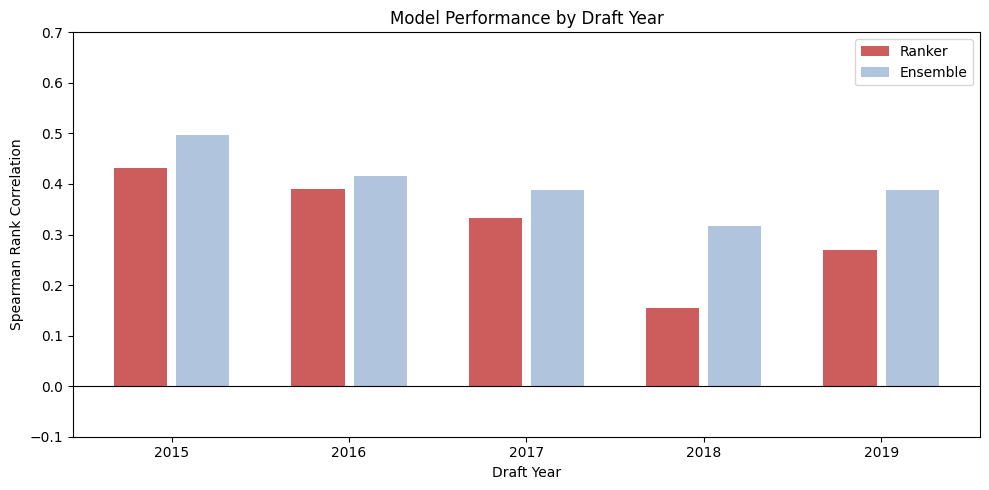

In [34]:
import matplotlib.pyplot as plt

years = [2015, 2016, 2017, 2018, 2019]
ranker_scores   = [0.431, 0.391, 0.333, 0.155, 0.269]
ensemble_scores = [0.497, 0.415, 0.388, 0.317, 0.388]

x = np.arange(len(years))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, ranker_scores,   width = 0.3, label='Ranker',   color='indianred')
ax.bar(x + width/2, ensemble_scores, width = 0.3 , label='Ensemble', color='lightsteelblue')
ax.axhline(y=0, color='black', linewidth=0.8)
ax.set_xlabel('Draft Year')
ax.set_ylabel('Spearman Rank Correlation')
ax.set_title('Model Performance by Draft Year')
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.legend()
ax.set_ylim(-0.1, 0.7)
plt.tight_layout()
plt.savefig('spearman_by_year.png', dpi=150)
plt.show()

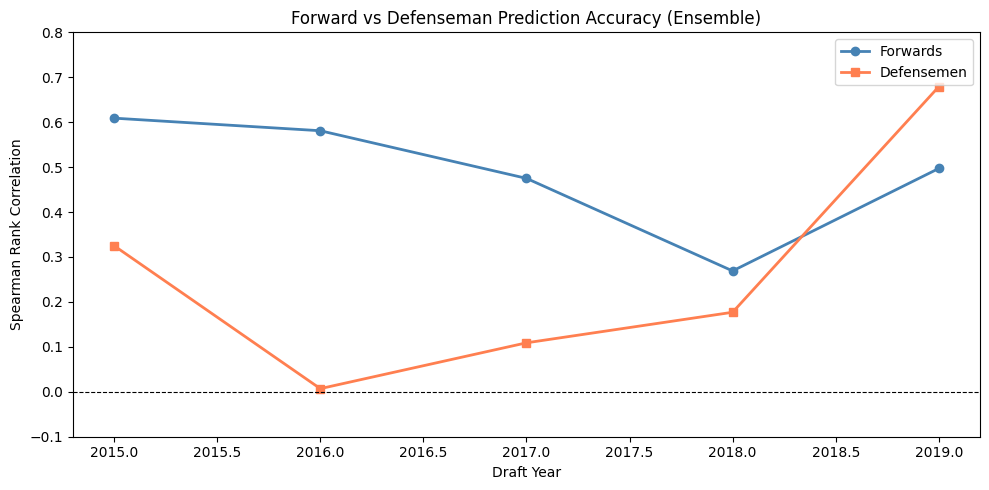

In [35]:
fwd_scores = [0.609, 0.581, 0.475, 0.269, 0.497]
def_scores = [0.325, 0.007, 0.109, 0.177, 0.679]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(years, fwd_scores, marker='o', label='Forwards', color='steelblue', linewidth=2)
ax.plot(years, def_scores, marker='s', label='Defensemen', color='coral', linewidth=2)
ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Draft Year')
ax.set_ylabel('Spearman Rank Correlation')
ax.set_title('Forward vs Defenseman Prediction Accuracy (Ensemble)')
ax.legend()
ax.set_ylim(-0.1, 0.8)
plt.tight_layout()
plt.savefig('fwd_vs_def.png', dpi=150)
plt.show()

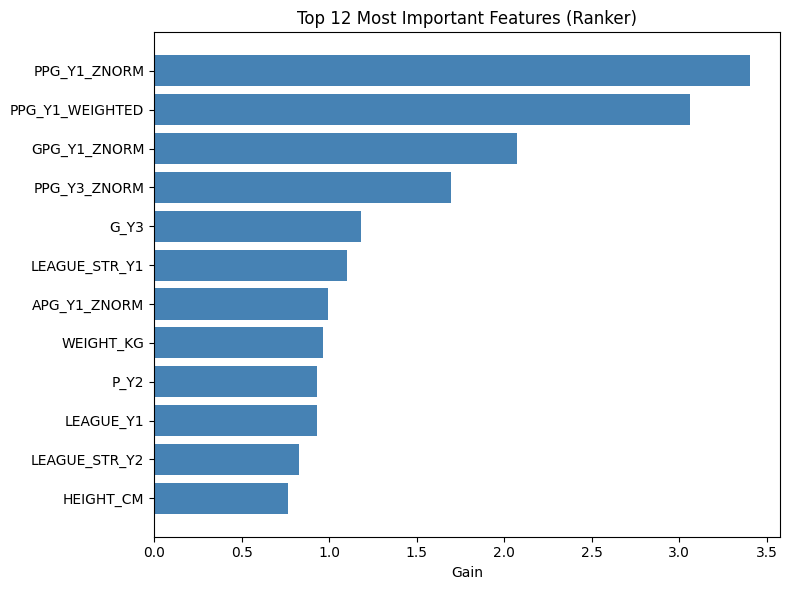

In [36]:
top_features = importance.head(12)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features['Feature'][::-1], top_features['Gain'][::-1], color='steelblue')
ax.set_xlabel('Gain')
ax.set_title('Top 12 Most Important Features (Ranker)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

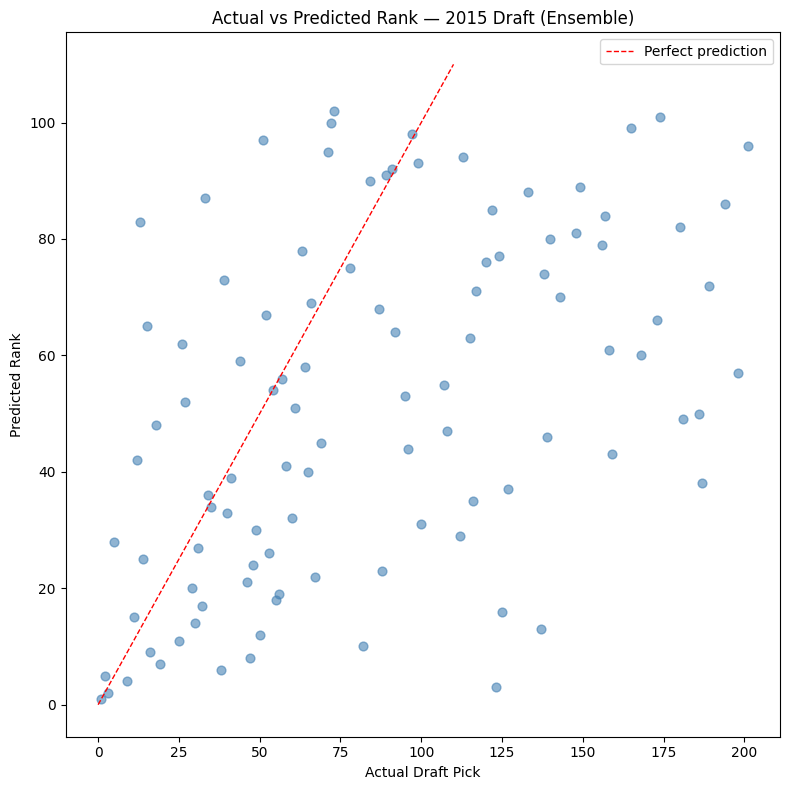

In [37]:
comp2015 = pred_df_ensemble[pred_df_ensemble["DRAFT_YEAR"] == 2015].copy()
comp2015["Predicted Rank"] = comp2015["Score"].rank(ascending=False).astype(int)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(comp2015["Actual Pick"], comp2015["Predicted Rank"], 
           alpha=0.6, color='steelblue', s=40)
ax.plot([0, 110], [0, 110], 'r--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Actual Draft Pick')
ax.set_ylabel('Predicted Rank')
ax.set_title('Actual vs Predicted Rank — 2015 Draft (Ensemble)')
ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted_2015.png', dpi=150)
plt.show()

Folder created


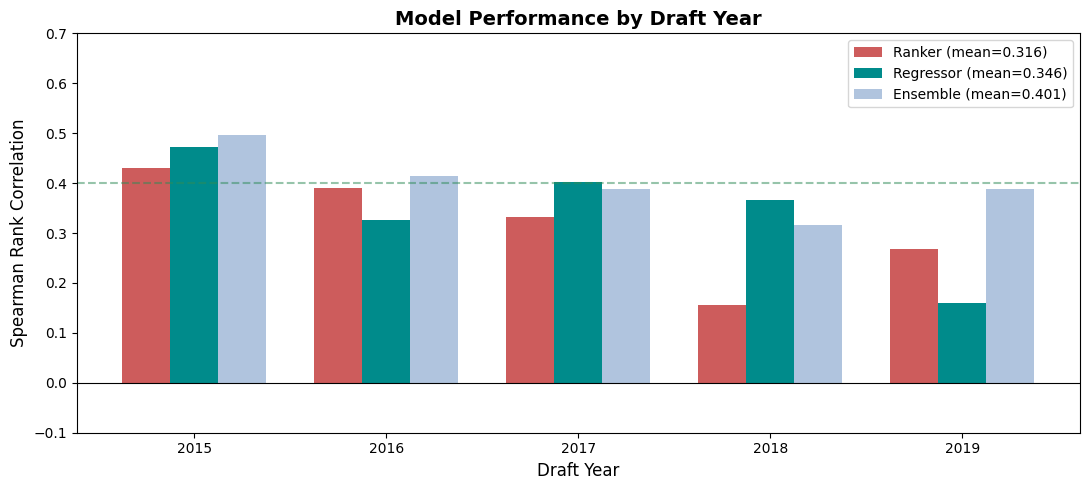

Saved: spearman_by_year.png


<Figure size 640x480 with 0 Axes>

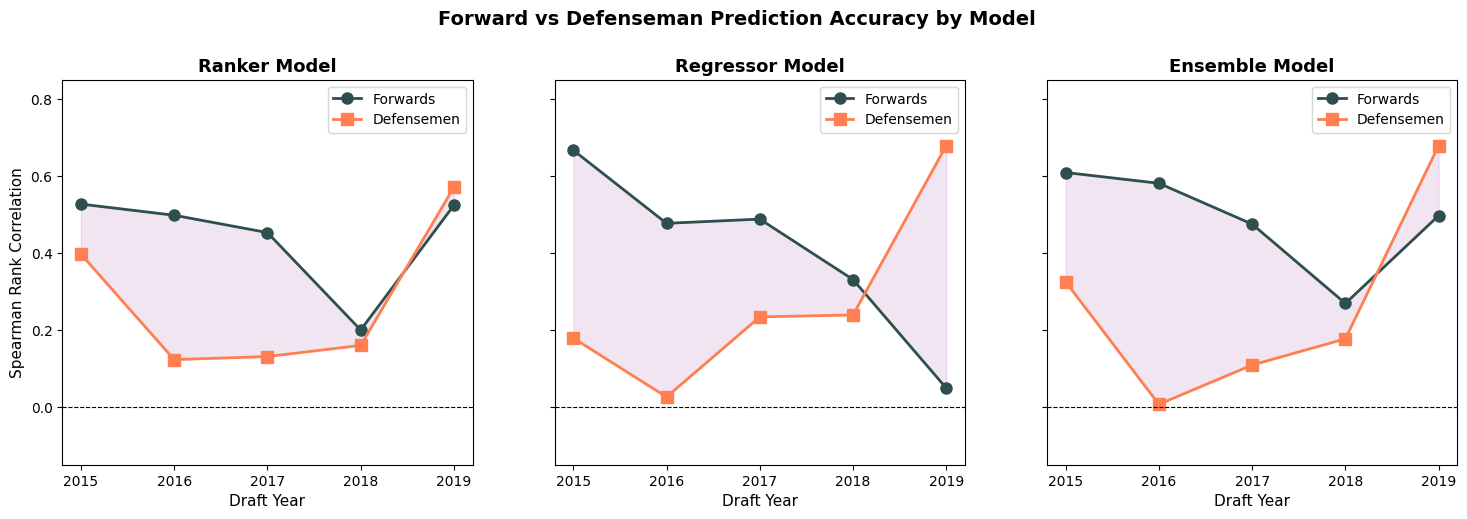

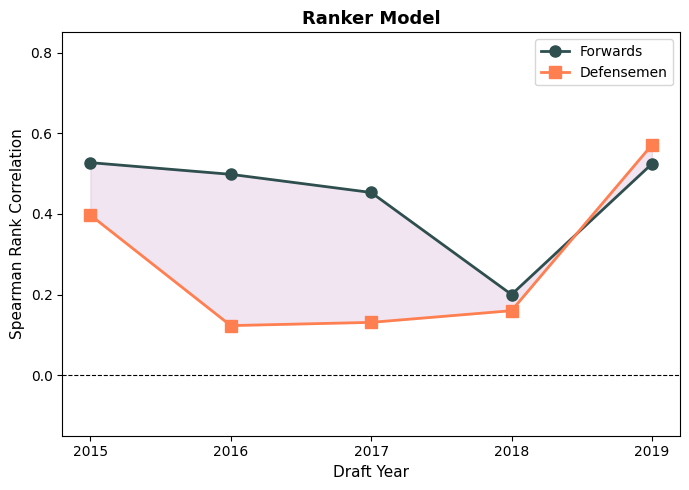

Saved: fwd_vs_def_ranker.png


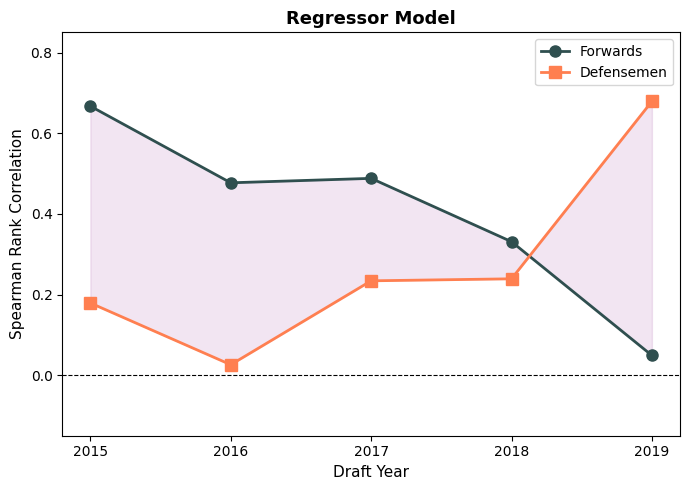

Saved: fwd_vs_def_regressor.png


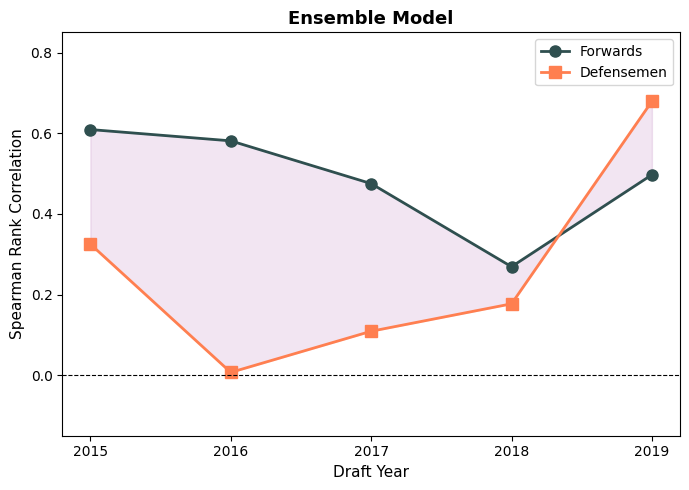

Saved: fwd_vs_def_ensemble.png


<Figure size 640x480 with 0 Axes>

Saved: fwd_vs_def.png


<Figure size 640x480 with 0 Axes>

Saved: fwd_vs_def.png


NameError: name 'ranker_gains' is not defined

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results', exist_ok=True)
print("Folder created")

# ── Data from your runs ───────────────────────────────────────────────────────
years = [2015, 2016, 2017, 2018, 2019]

ranker_spearman   = [0.431, 0.391, 0.333, 0.155, 0.269]
reg_spearman      = [0.473, 0.327, 0.402, 0.367, 0.160]
ensemble_spearman = [0.497, 0.415, 0.388, 0.317, 0.388]

# Forward vs Defense — Ensemble
ens_fwd_spearman = [0.609, 0.581, 0.475, 0.269, 0.497]
ens_def_spearman = [0.325, 0.007, 0.109, 0.177, 0.679]

# Forward vs Defense — Regressor
reg_fwd_spearman = [0.667, 0.477, 0.488, 0.331, 0.049]
reg_def_spearman = [0.179, 0.026, 0.234, 0.239, 0.679]

# Feature importance from your ranker
features = [
    'PPG_Y1_ZNORM', 'PPG_Y2', 'PPG_Y1_WEIGHTED',
    'APG_Y1_WEIGHTED', 'LEAGUE_STR_Y1', 'APG_Y3_ZNORM',
    'WEIGHT_KG', 'GPG_Y1_ZNORM', 'GPG_Y1_WEIGHTED',
    'GP_Y3', 'HEIGHT_CM', 'G_Y1', 'LEAGUE_STR_Y2'
]
gains = [
    4.263, 3.540, 2.863,
    1.594, 1.395, 1.308,
    1.219, 1.144, 1.125,
    1.088, 0.996, 0.897, 0.855
]

# ── Figure 1: Spearman by year ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(years))
w = 0.25

bars1 = ax.bar(x - w,  ranker_spearman,   w, label=f'Ranker (mean={np.mean(ranker_spearman):.3f})',     color='indianred')
bars2 = ax.bar(x,      reg_spearman,      w, label=f'Regressor (mean={np.mean(reg_spearman):.3f})',     color='darkcyan')
bars3 = ax.bar(x + w,  ensemble_spearman, w, label=f'Ensemble (mean={np.mean(ensemble_spearman):.3f})', color='lightsteelblue')

ax.axhline(y=0, color='black', linewidth=0.8)
ax.axhline(y=np.mean(ensemble_spearman), color='seagreen',
           linewidth=1.5, linestyle='--', alpha=0.5)
ax.set_xlabel('Draft Year', fontsize=12)
ax.set_ylabel('Spearman Rank Correlation', fontsize=12)
ax.set_title('Model Performance by Draft Year', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.legend(loc='upper right')
ax.set_ylim(-0.1, 0.7)
plt.tight_layout()
plt.savefig('spearman_by_year.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: spearman_by_year.png")
plt.savefig('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/spearman_by_year.png', 
            dpi=150, bbox_inches='tight')

# ── Figure 2: Forward vs Defense — All 3 models ───────────────────────────────

# Ranker forward vs defense data
rnk_fwd_spearman = [0.527, 0.498, 0.453, 0.200, 0.524]
rnk_def_spearman = [0.397, 0.123, 0.131, 0.160, 0.571]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, fwd, dfc, title in zip(
    axes,
    [rnk_fwd_spearman, reg_fwd_spearman, ens_fwd_spearman],
    [rnk_def_spearman, reg_def_spearman, ens_def_spearman],
    ['Ranker Model', 'Regressor Model', 'Ensemble Model']
):
    ax.plot(years, fwd, marker='o', label='Forwards',
            color='darkslategray', linewidth=2, markersize=8)
    ax.plot(years, dfc, marker='s', label='Defensemen',
            color='coral', linewidth=2, markersize=8)
    ax.fill_between(years, fwd, dfc, alpha=0.1, color='purple')
    ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Draft Year', fontsize=11)
    ax.legend()
    ax.set_ylim(-0.15, 0.85)
    ax.set_xticks(years)
    ax.set_xticklabels(years)

axes[0].set_ylabel('Spearman Rank Correlation', fontsize=11)

fig.suptitle('Forward vs Defenseman Prediction Accuracy by Model',
             fontsize=14, fontweight='bold', y=1.02)

# After your loop, save each subplot separately
for i, (fwd, dfc, title, filename) in enumerate(zip(
    [rnk_fwd_spearman, reg_fwd_spearman, ens_fwd_spearman],
    [rnk_def_spearman, reg_def_spearman, ens_def_spearman],
    ['Ranker Model', 'Regressor Model', 'Ensemble Model'],
    ['fwd_vs_def_ranker', 'fwd_vs_def_regressor', 'fwd_vs_def_ensemble']
)):
    fig_single, ax_single = plt.subplots(figsize=(7, 5))
    ax_single.plot(years, fwd, marker='o', label='Forwards',
                   color='darkslategray', linewidth=2, markersize=8)
    ax_single.plot(years, dfc, marker='s', label='Defensemen',
                   color='coral', linewidth=2, markersize=8)
    ax_single.fill_between(years, fwd, dfc, alpha=0.1, color='purple')
    ax_single.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
    ax_single.set_title(title, fontsize=13, fontweight='bold')
    ax_single.set_xlabel('Draft Year', fontsize=11)
    ax_single.set_ylabel('Spearman Rank Correlation', fontsize=11)
    ax_single.legend()
    ax_single.set_ylim(-0.15, 0.85)
    ax_single.set_xticks(years)
    ax_single.set_xticklabels(years)
    plt.tight_layout()
    plt.savefig(f'/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/{filename}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {filename}.png")
    
plt.tight_layout()
plt.savefig('fwd_vs_def.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fwd_vs_def.png")
# Ensemble
axes[0].plot(years, ens_fwd_spearman, marker='o', label='Forwards',
             color='darkslategray', linewidth=2, markersize=8)
axes[0].plot(years, ens_def_spearman, marker='s', label='Defensemen',
             color='coral', linewidth=2, markersize=8)
axes[0].fill_between(years, ens_fwd_spearman, ens_def_spearman,
                     alpha=0.1, color='purple')
axes[0].axhline(y=0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Ensemble Model', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Draft Year', fontsize=11)
axes[0].set_ylabel('Spearman Rank Correlation', fontsize=11)
axes[0].legend()
axes[0].set_ylim(-0.15, 0.85)

# Regressor
axes[1].plot(years, reg_fwd_spearman, marker='o', label='Forwards',
             color='darkslategray', linewidth=2, markersize=8)
axes[1].plot(years, reg_def_spearman, marker='s', label='Defensemen',
             color='coral', linewidth=2, markersize=8)
axes[1].fill_between(years, reg_fwd_spearman, reg_def_spearman,
                     alpha=0.1, color='purple')
axes[1].axhline(y=0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Regressor Model', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Draft Year', fontsize=11)
axes[1].legend()
axes[1].set_ylim(-0.15, 0.85)

fig.suptitle('Forward vs Defenseman Prediction Accuracy',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fwd_vs_def.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fwd_vs_def.png")

# ── Figure 3: Feature importance — save separately ───────────────────────────

# Normalize both to 0-1
ranker_norm = np.array(ranker_gains) / max(ranker_gains)
reg_norm    = np.array(reg_gains)    / max(reg_gains)

# Ranker importance
fig, ax = plt.subplots(figsize=(9, 6))
colors_rnk = ['steelblue' if g > 0.5 else 'lightsteelblue' for g in ranker_norm]
ax.barh(ranker_features[::-1], ranker_norm[::-1], color=colors_rnk[::-1])
ax.axvline(x=np.mean(ranker_norm), color='red', linestyle='--',
           linewidth=1.5, label=f'Mean ({np.mean(ranker_norm):.2f})')
ax.set_xlabel('Normalized Gain (0-1)', fontsize=11)
ax.set_title('Ranker Model — Feature Importance', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/feature_importance_ranker.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_importance_ranker.png")

# Regressor importance
fig, ax = plt.subplots(figsize=(9, 6))
colors_reg = ['coral' if g > 0.5 else 'lightsalmon' for g in reg_norm]
ax.barh(reg_features[::-1], reg_norm[::-1], color=colors_reg[::-1])
ax.axvline(x=np.mean(reg_norm), color='red', linestyle='--',
           linewidth=1.5, label=f'Mean ({np.mean(reg_norm):.2f})')
ax.set_xlabel('Normalized Gain (0-1)', fontsize=11)
ax.set_title('Regressor Model — Feature Importance', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/feature_importance_regressor.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_importance_regressor.png")

# ── Figure 4: Actual vs Predicted scatter — all 3 models (2015) ──────────────

# Get 2015 predictions for each model
# ── Figure 4: Actual vs Predicted — save separately ──────────────────────────
# ── Figure 4: Actual vs Predicted — all 3 models together ────────────────────

comp_rnk = pred_df[pred_df["DRAFT_YEAR"] == 2015].copy()
comp_rnk["Predicted Rank"] = comp_rnk["Score"].rank(ascending=False).astype(int)

comp_reg = pred_df_reg[pred_df_reg["DRAFT_YEAR"] == 2015].copy()
comp_reg["Predicted Rank"] = comp_reg["Predicted Pick"].rank(ascending=True).astype(int)

comp_ens = pred_df_ensemble[pred_df_ensemble["DRAFT_YEAR"] == 2015].copy()
comp_ens["Predicted Rank"] = comp_ens["Score"].rank(ascending=False).astype(int)

configs = [
    (comp_rnk, 'Ranker Model',    'steelblue'),
    (comp_reg, 'Regressor Model', 'coral'),
    (comp_ens, 'Ensemble Model',  'seagreen'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, sharex=True)

for ax, (df, title, color) in zip(axes, configs):
    ax.scatter(df["Actual Pick"], df["Predicted Rank"],
               alpha=0.6, color=color, s=50, zorder=3)
    ax.plot([0, 110], [0, 110], 'r--', linewidth=1.5,
            label='Perfect prediction', zorder=2)

    top10 = df.nsmallest(10, "Actual Pick")
    for _, row in top10.iterrows():
        name = row["PLAYER_NAME"].split("(")[0].strip()
        ax.annotate(name,
                    xy=(row["Actual Pick"], row["Predicted Rank"]),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=7, alpha=0.9)

    corr, _ = spearmanr(df["Actual Pick"], df["Predicted Rank"])
    ax.text(0.05, 0.95, f'Spearman = {corr:.3f}',
            transform=ax.transAxes, fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax.set_title(f'{title}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Actual Draft Pick', fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Predicted Rank', fontsize=11)
fig.suptitle('Actual vs Predicted Rank — 2015 Draft',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/actual_vs_predicted_2015.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: actual_vs_predicted_2015.png")

# ── Figure 5: Model comparison table ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

table_data = [
    ['Model',      '2015',  '2016',  '2017',  '2018',  '2019',  'Mean'],
    ['Ranker',     '0.431', '0.391', '0.333', '0.155', '0.269', '0.380'],
    ['Regressor',  '0.473', '0.327', '0.402', '0.367', '0.160', '0.346'],
    ['Ensemble',   '0.497', '0.415', '0.388', '0.317', '0.388', '0.401'],
]

table = ax.table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(12)

# Style header row
for j in range(7):
    table[0, j].set_facecolor('#cce5ff')
    table[0, j].set_text_props(fontweight='bold')

# Highlight ensemble row
for j in range(7):
    table[3, j].set_facecolor('#d4edda')

# Highlight best value per year column
best_rows = [1, 1, 3, 2, 2, 3]  # which row has best value per year col
for col, row in enumerate(best_rows, start=1):
    table[row, col].set_text_props(fontweight='bold')

plt.title('Spearman Rank Correlation by Model and Draft Year',
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('/home/csusers/jiayi.teh/CPSC502/nhl-prospects/results/model_comparison_table.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model_comparison_table.png")

In [ ]:
print("pred_df columns:", pred_df.columns.tolist())
print("pred_df_reg columns:", pred_df_reg.columns.tolist())
print("pred_df_ensemble columns:", pred_df_ensemble.columns.tolist())

print("\npred_df 2015 rows:", len(pred_df[pred_df["DRAFT_YEAR"] == 2015]))
print("pred_df_reg 2015 rows:", len(pred_df_reg[pred_df_reg["DRAFT_YEAR"] == 2015]))
print("pred_df_ensemble 2015 rows:", len(pred_df_ensemble[pred_df_ensemble["DRAFT_YEAR"] == 2015]))

pred_df columns: ['PLAYER_NAME', 'DRAFT_YEAR', 'Actual Pick', 'Score']
pred_df_reg columns: ['PLAYER_NAME', 'DRAFT_YEAR', 'Actual Pick', 'Predicted Pick']
pred_df_ensemble columns: ['PLAYER_NAME', 'DRAFT_YEAR', 'Actual Pick', 'Score']

pred_df 2015 rows: 102
pred_df_reg 2015 rows: 102
pred_df_ensemble 2015 rows: 102


In [ ]:
# Get regressor feature importance
reg_importance = pd.DataFrame(
    model_reg.get_score(importance_type='gain').items(),
    columns=['Feature', 'Gain']
).sort_values('Gain', ascending=False)

print("Top 15 Regressor Features:")
print(reg_importance.head(15).to_string(index=False))

Top 15 Regressor Features:
        Feature         Gain
   PPG_Y1_ZNORM 13677.208008
PPG_Y1_WEIGHTED 11113.799805
APG_Y1_WEIGHTED  9666.108398
  LEAGUE_STR_Y1  9191.208984
      LEAGUE_Y1  8022.349121
      HEIGHT_CM  7955.318848
  LEAGUE_STR_Y2  6492.520020
      WEIGHT_KG  6444.646484
   APG_Y1_ZNORM  6223.812012
          GP_Y2  5599.451172
PPG_Y3_WEIGHTED  5595.497070
   PPG_Y3_ZNORM  5420.699707
   GPG_Y2_ZNORM  5368.902832
   PPG_Y2_ZNORM  5300.616211
           A_Y3  5190.090332


In [ ]:
all_results = []
for year in sorted(pred_df["DRAFT_YEAR"].unique()):
    yr_df = pred_df[pred_df["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    corr, _ = spearmanr(yr_df["Actual Pick"], yr_df["Predicted Rank"])
    n = len(yr_df)
    top_n = max(10, n // 3)
    actual_top    = set(yr_df.nsmallest(top_n, "Actual Pick")["PLAYER_NAME"])
    predicted_top = set(yr_df.nsmallest(top_n, "Predicted Rank")["PLAYER_NAME"])
    overlap = len(actual_top & predicted_top)
    all_results.append({"Year": year, "N": n, "Spearman": round(corr, 3),
                        f"Top-{top_n} Overlap": f"{overlap}/{top_n}"})

results_df = pd.DataFrame(all_results)
print(results_df.to_string(index=False))
print(f"\nMean Spearman: {results_df['Spearman'].mean():.3f}")

 Year   N  Spearman Top-34 Overlap Top-33 Overlap Top-30 Overlap Top-19 Overlap Top-10 Overlap
 2015 102     0.457          21/34            NaN            NaN            NaN            NaN
 2016 101     0.408            NaN          18/33            NaN            NaN            NaN
 2017  90     0.344            NaN            NaN          15/30            NaN            NaN
 2018  59     0.254            NaN            NaN            NaN           9/19            NaN
 2019  19     0.405            NaN            NaN            NaN            NaN           6/10

Mean Spearman: 0.374


In [ ]:
from scipy.stats import spearmanr

corr, _ = spearmanr(comparison["Actual Pick"], comparison["Predicted Rank"])
print(f"Spearman: {corr:.3f}")

actual_top10    = set(comparison.nsmallest(10, "Actual Pick")["PLAYER_NAME"])
predicted_top10 = set(comparison.nsmallest(10, "Predicted Rank")["PLAYER_NAME"])
print(f"Top-10 overlap: {len(actual_top10 & predicted_top10)}/10")

actual_top32    = set(comparison.nsmallest(32, "Actual Pick")["PLAYER_NAME"]) 
predicted_top32 = set(comparison.nsmallest(32, "Predicted Rank")["PLAYER_NAME"])
print(f"Top-19 overlap (full 2019 class): {len(actual_top32 & predicted_top32)}/19")

Spearman: 0.367
Top-10 overlap: 5/10
Top-19 overlap (full 2019 class): 22/19


In [ ]:
all_results = []

for year in sorted(pred_df["DRAFT_YEAR"].unique()):
    yr_df = pred_df[pred_df["DRAFT_YEAR"] == year].copy()
    yr_df["Predicted Rank"] = yr_df["Score"].rank(ascending=False).astype(int)
    
    corr, _ = spearmanr(yr_df["Actual Pick"], yr_df["Predicted Rank"])
    
    n = len(yr_df)
    top_n = max(10, n // 3)  # top third of each class
    actual_top    = set(yr_df.nsmallest(top_n, "Actual Pick")["PLAYER_NAME"])
    predicted_top = set(yr_df.nsmallest(top_n, "Predicted Rank")["PLAYER_NAME"])
    overlap = len(actual_top & predicted_top)
    
    all_results.append({
        "Year": year, "N": n,
        "Spearman": round(corr, 3),
        f"Top-{top_n} Overlap": f"{overlap}/{top_n}"
    })

results_df = pd.DataFrame(all_results)
print(results_df.to_string(index=False))
print(f"\nMean Spearman: {results_df['Spearman'].mean():.3f}")

 Year   N  Spearman Top-34 Overlap Top-33 Overlap Top-30 Overlap Top-19 Overlap Top-10 Overlap
 2015 102     0.457          21/34            NaN            NaN            NaN            NaN
 2016 101     0.408            NaN          18/33            NaN            NaN            NaN
 2017  90     0.344            NaN            NaN          15/30            NaN            NaN
 2018  59     0.254            NaN            NaN            NaN           9/19            NaN
 2019  19     0.405            NaN            NaN            NaN            NaN           6/10

Mean Spearman: 0.374


In [ ]:

import xgboost as xgb
import pandas as pd
import numpy as np

# 1. Identify the 'Junk' (The Name Tags and Spoilers)
junk_cols = ['PLAYER_ID', 'PLAYER_NAME', 'DRAFT_YEAR', 'DRAFT_ROUND']

# 2. Separate X (Features) and y (Target)
X = final_df.drop(columns=['DRAFT_OVERALL'] + junk_cols)
y = final_df['DRAFT_OVERALL'] 

# 3. The "Category" Trick 
# We find every column that is text (like LEAGUE_Y1) and tell Pandas it's a 'category'
# XGBoost needs this 'category' label to work!
for col in X.select_dtypes(include=['object']).columns:
    X[col] = X[col].astype('category')